# 04 · Perguntas de negócio que atravessam domínios

**Objetivo:** mostrar por que vale a pena ter um grafo. Cada pergunta abaixo cruza pelo menos dois domínios e exigiria juntar MES, CMMS, QMS, almoxarifado e medição de energia, se cada um tivesse seu próprio modelo de máquina.

A planta de exemplo carrega uma pequena história, e o notebook termina com ela.

In [1]:
# Configuração: deixa a raiz do repositório no caminho de import
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import pandas as pd
pd.set_option("display.max_colwidth", 80)
from lab.graph import load_ontology, load_plant, query, MFG, PRD, MNT, QA, NRG, INV, ID
from lab import queries as q
import matplotlib.pyplot as plt
g = load_plant()
curto = lambda df: df.apply(lambda c: c.map(lambda v: v.split("/id/")[-1].split("#")[-1] if isinstance(v, str) else v))

## 1. Manutenção × produção: paradas não planejadas por linha e modo de falha

In [2]:
print(q.DOWNTIME_BY_FAILURE_MODE)
paradas = pd.DataFrame(query(g, q.DOWNTIME_BY_FAILURE_MODE)).astype({"stops": int, "total_min": int})
paradas


SELECT ?line ?mode (COUNT(?d) AS ?stops) (SUM(?minutes) AS ?total_min) WHERE {
  ?d a mnt:Downtime ; mnt:planned false ; mnt:causedBy/rdfs:label ?mode ;
     mfg:occurredOn/mfg:partOf/rdfs:label ?line ;
     mfg:startTime ?s ; mfg:endTime ?e .
  BIND((HOURS(?e) * 60 + MINUTES(?e)) - (HOURS(?s) * 60 + MINUTES(?s)) AS ?minutes)
} GROUP BY ?line ?mode ORDER BY DESC(?total_min)



,line,mode,stops,total_min
0,Line 1,Seal wear,3,54
1,Line 3,Motor overload,1,9
2,Line 1,Bottle jam,1,7
3,Line 2,Bottle jam,1,6


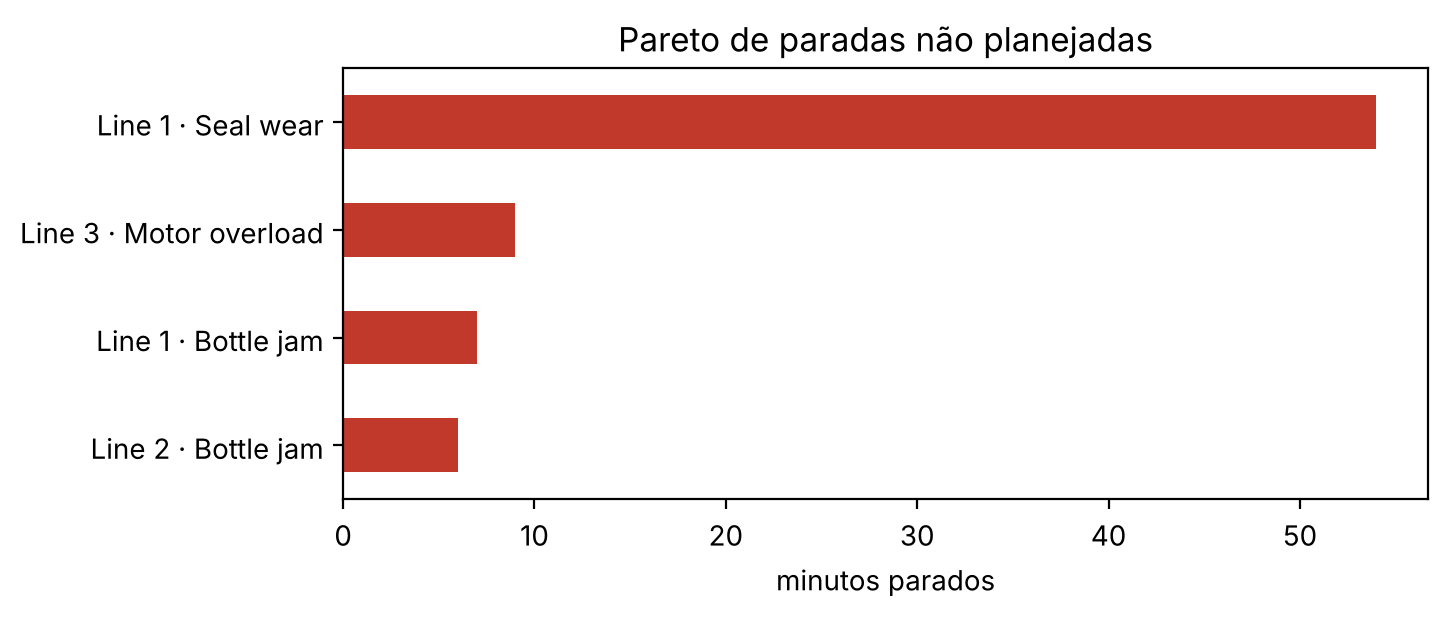

In [3]:
ax = paradas.assign(rotulo=paradas.line + " · " + paradas["mode"]).plot.barh(x="rotulo", y="total_min", legend=False, color="#c0392b", figsize=(7, 2.8))
ax.invert_yaxis(); ax.set_xlabel("minutos parados"); ax.set_ylabel(""); ax.set_title("Pareto de paradas não planejadas"); plt.show()

**Leitura:** "desgaste de vedação" na linha 1 domina (3 paradas, 54 min). O caminho `mfg:occurredOn/mfg:partOf/rdfs:label` vai da parada até a máquina, da máquina até a linha, e da linha até o nome, numa linha só de SPARQL. O almoço (`planned true`) fica fora.

## 2. Manutenção → componente: o que trocar

In [4]:
pd.DataFrame(query(g, q.COMPONENT_TO_REPLACE))

,mode,component,stops,order
0,Seal wear,Seal Kit,3,MO-0077
1,Motor overload,Main Motor,1,NaN


O modo de falha aponta para o componente afetado (`mnt:affects`), e a ordem de manutenção `MO-0077` registra a troca do kit de vedação. Em CMMS sem modelo de falha, essa ligação depende de alguém ler o texto livre da ordem.

## 3. Manutenção × produção × qualidade: os lotes feitos durante as falhas

In [5]:
lotes = pd.DataFrame(query(g, q.LOTS_HIT_BY_FAILURE))
lotes

,lot,run,result,leaks,stops_during_run,failure_modes
0,L-1041,R-1041,PASS,4.0,0,-
1,L-1042,R-1042,HOLD,37.0,1,Seal wear
2,L-1043,R-1043,REJECT,61.0,3,"Seal wear, Bottle jam"
3,L-2041,R-2041,PASS,1.0,0,-
4,L-2042,R-2042,PASS,NaN,1,Bottle jam
5,L-3041,R-3041,PASS,2.0,1,Motor overload


**Leitura:** a consulta liga cada corrida às paradas que aconteceram **dentro do intervalo dela** (`?ds < ?re && ?de > ?rs`), e cada lote à sua inspeção.

* `L-1041`: nenhuma parada durante a corrida, 4 vazamentos, **PASS**.
* `L-1042`: uma parada por desgaste de vedação, 37 vazamentos, **HOLD**.
* `L-1043`: três paradas (duas de vedação), 61 vazamentos, **REJECT**.
* Linhas 2 e 3 tiveram paradas por outros motivos e passaram na inspeção.

## 4. Estoque × qualidade: genealogia de um lote de matéria-prima

In [6]:
gen = pd.DataFrame(query(g, q.GENEALOGY_OF_MATERIAL_LOT))
gen

,material_lot,supplier,lot,line,result
0,ML-2207,Cap Co,L-1041,Line 1,PASS
1,ML-2207,Cap Co,L-1042,Line 1,HOLD
2,ML-2207,Cap Co,L-1043,Line 1,REJECT
3,ML-2210,Seal Systems,L-2041,Line 2,PASS
4,ML-2210,Seal Systems,L-2042,Line 2,PASS
5,ML-2215,Seal Systems,L-3041,Line 3,PASS


Todos os lotes ruins consumiram o lote de tampas **ML-2207** (fornecedor Cap Co). Os lotes da linha 2 e 3 usaram tampas de outro fornecedor e passaram.

## 5. A pergunta difícil: foi a vedação ou foi a tampa?

In [7]:
historia = lotes.merge(gen[["lot", "material_lot", "supplier", "line"]], on="lot")
historia[["lot", "line", "material_lot", "supplier", "stops_during_run", "failure_modes", "leaks", "result"]]

,lot,line,material_lot,supplier,stops_during_run,failure_modes,leaks,result
0,L-1041,Line 1,ML-2207,Cap Co,0,-,4.0,PASS
1,L-1042,Line 1,ML-2207,Cap Co,1,Seal wear,37.0,HOLD
2,L-1043,Line 1,ML-2207,Cap Co,3,"Seal wear, Bottle jam",61.0,REJECT
3,L-2041,Line 2,ML-2210,Seal Systems,0,-,1.0,PASS
4,L-2042,Line 2,ML-2210,Seal Systems,1,Bottle jam,NaN,PASS
5,L-3041,Line 3,ML-2215,Seal Systems,1,Motor overload,2.0,PASS


**Esta é a lição mais importante do notebook.** O grafo encontrou **duas** explicações plausíveis para os vazamentos e não consegue escolher entre elas:

* **Hipótese A, manutenção:** os vazamentos crescem junto com as paradas por desgaste de vedação (0 → 1 → 2 paradas de vedação, 4 → 37 → 61 vazamentos).
* **Hipótese B, material:** todos os lotes com problema usaram tampas ML-2207, e nenhum lote com outra tampa teve problema.

Os dois fatores estão **confundidos**: a tampa ML-2207 só foi usada na linha 1, que é também a única com desgaste de vedação. Nenhuma consulta resolve isso. O que o grafo faz é **mostrar a pergunta certa em minutos**, em vez de semanas de reunião entre manutenção, qualidade e suprimentos. O próximo passo é um experimento: rodar ML-2207 na linha 2, ou a linha 1 com o kit de vedação novo e outra tampa.

## 6. Energia × produção: kWh por mil peças boas

In [8]:
energia = pd.DataFrame(query(g, q.ENERGY_PER_PART)).astype({"kwh_per_1000": float, "kwh": float})
energia

,line,kwh,good,kwh_per_1000
0,Line 2,655.0,207500,3.156627
1,Line 1,612.0,177600,3.445946
2,Line 3,1180.0,205000,5.756098


A linha 3 gasta cerca de **80 % mais energia por peça** que a linha 2, fazendo o mesmo produto. O medidor está ligado à **linha** (`nrg:meters`), e as peças estão nas **corridas da máquina** da linha; o grafo soma as corridas por linha e divide. Sem identidade comum, isso seria uma planilha manual.

## 7. Ponte para o UNS: onde assinar

In [9]:
pd.DataFrame(query(g, q.UNS_TOPICS_FOR_FILLERS))

,equipment,topic
0,Filler L3,acme/curitiba/packaging/line-3/filler-01/state
1,Filler L1,acme/sao-paulo/packaging/line-1/filler-01/state
2,Filler L2,acme/sao-paulo/packaging/line-2/filler-01/state


O grafo não guarda o valor ao vivo (por enquanto `value` está vazio): ele sabe **onde** o valor está. Uma aplicação pergunta ao grafo "qual o tópico do estado de todas as enchedoras" e assina no broker. O notebook 05 liga essa ponte e preenche `value` em tempo real.

## Resumo

* Consultas que cruzam domínios ficam curtas porque o **tempo** e o **ativo** são comuns a todos os eventos.
* Caminhos de propriedade (`a/b/c`) substituem cadeias de JOIN.
* O grafo **acelera a investigação**, mas não substitui o raciocínio: correlação entre fatores confundidos continua precisando de experimento.